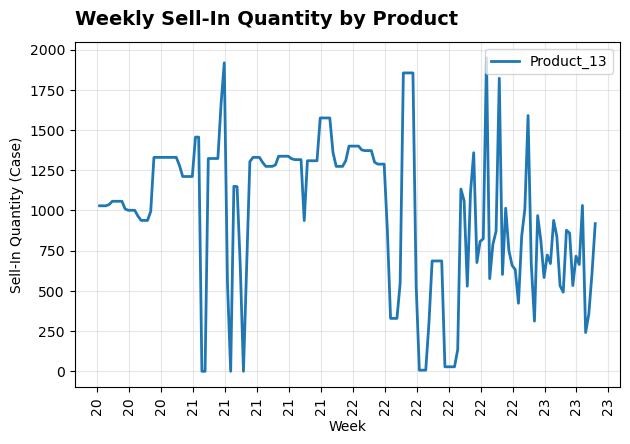

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load the Excel file
gt_sales = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")

# Filter for sell-in data
sellin_data = gt_sales[gt_sales['sales_key'] == 'sellin']

# Create the plot
fig, ax = plt.subplots()

# Plot lines for each product
for product in sellin_data['Product'].unique():
    product_data = sellin_data[sellin_data['Product'] == product]
    ax.plot(product_data['date'], product_data['value'],
            linewidth=2, label=product)

# Title
ax.text(0.0, 1.05, "Weekly Sell-In Quantity by Product",
        transform=ax.transAxes, fontweight='bold',
        fontsize=14, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Sell-In Quantity (Case)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Adjust layout
plt.subplots_adjust(top=1.9)
plt.tight_layout()
plt.show()


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load the Excel file
gt_sales = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")

# Rename for consistency
gt_sales.rename(columns={'Product': 'product_id'}, inplace=True)
gt_sales['date'] = pd.to_datetime(gt_sales['date'])

# Pivot to wide format
sales_wide = (gt_sales.pivot_table(index=['date', 'sales_key'],
                                   columns='product_id',
                                   values='value',
                                   aggfunc='first')
              .reset_index()
              .fillna(0))

sales_wide.columns.name = None

# Simulate two SKUs from the single product
sales_wide['spice_masala_regular_100g'] = sales_wide['Product_13'] * 0.7
sales_wide['spice_masala_bundle_100g+50gfree'] = sales_wide['Product_13'] * 0.3


In [3]:
# Create combined metrics and promotion indicators
sales_combined = sales_wide.assign(
    combined_spice_masala=lambda x: x['spice_masala_regular_100g'] + x['spice_masala_bundle_100g+50gfree'],
    promo_key=lambda x: np.where(x['spice_masala_bundle_100g+50gfree'] == 0, 0, 1),
    promo_type=lambda x: np.where(x['spice_masala_bundle_100g+50gfree'] == 0, None, 'Bundle Sales')
)


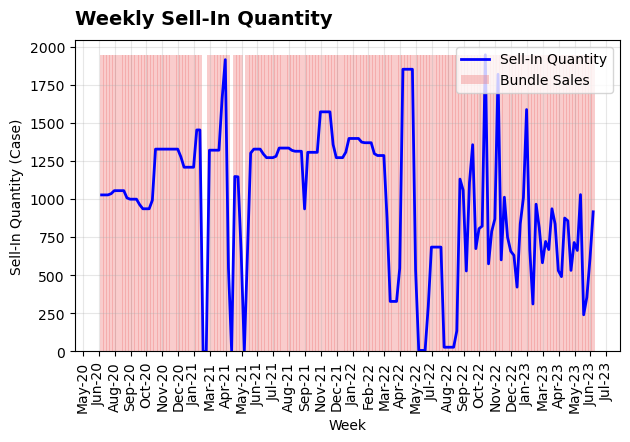

In [4]:
# Filter for sell-in data
sellin_data = sales_combined[sales_combined['sales_key'] == 'sellin'].copy()
max_combined_value = sellin_data['combined_spice_masala'].max()

# Filter promotion periods for bars
promo_data = sellin_data[sellin_data['promo_key'] == 1].copy()

# Create the plot
fig, ax = plt.subplots()

# Promotion overlay bars (only for promotion periods)
if not promo_data.empty:
    ax.bar(promo_data['date'], max_combined_value,
           color='#F08080', alpha=0.4, width=9, label='Bundle Sales')

# Main line plot
ax.plot(sellin_data['date'], sellin_data['combined_spice_masala'],
        color='blue', linewidth=2, label='Sell-In Quantity')

# Title
ax.text(0.0, 1.05, "Weekly Sell-In Quantity",
        transform=ax.transAxes, fontweight='bold',
        fontsize=14, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Sell-In Quantity (Case)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Adjust layout
plt.subplots_adjust(top=1.9)
plt.tight_layout()
plt.show()


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load the Excel file
gt_sales = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")

# Rename for consistency
gt_sales.rename(columns={'Product': 'product_id'}, inplace=True)
gt_sales['date'] = pd.to_datetime(gt_sales['date'])

# Pivot to wide format
sales_wide = (gt_sales.pivot_table(index=['date', 'sales_key'],
                                   columns='product_id',
                                   values='value',
                                   aggfunc='first')
              .reset_index()
              .fillna(0))

sales_wide.columns.name = None

# Simulate two SKUs from the single product
sales_wide['spice_masala_regular_100g'] = sales_wide['Product_13'] * 0.7
sales_wide['spice_masala_bundle_100g+50gfree'] = sales_wide['Product_13'] * 0.3

# Create combined metrics and promotion indicators
sales_combined = sales_wide.assign(
    combined_spice_masala=lambda x: x['spice_masala_regular_100g'] + x['spice_masala_bundle_100g+50gfree'],
    promo_key=lambda x: np.where(x['spice_masala_bundle_100g+50gfree'] == 0, 0, 1),
    promo_type=lambda x: np.where(x['spice_masala_bundle_100g+50gfree'] == 0, None, 'Bundle Sales')
)


In [6]:
# Filter for sell-out data
sellout_data = sales_combined[sales_combined['sales_key'] == 'sellout'].copy()
max_sellout_value = sellout_data['combined_spice_masala'].max()

# Filter promotion periods for bars
sellout_promo_data = sellout_data[sellout_data['promo_key'] == 1].copy()


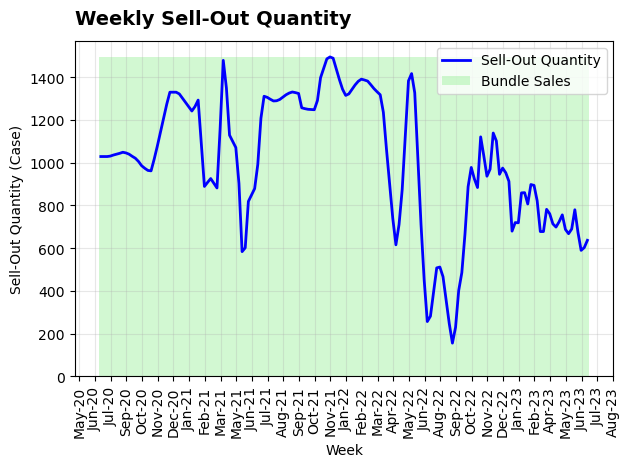

In [7]:
# Create the plot
fig, ax = plt.subplots()

# Promotion overlay bars (light green for sell-out)
if not sellout_promo_data.empty:
    ax.bar(sellout_promo_data['date'], max_sellout_value, 
           color='#90EE90', alpha=0.4, width=7, label='Bundle Sales')

# Main line plot
ax.plot(sellout_data['date'], sellout_data['combined_spice_masala'], 
        color='blue', linewidth=2, label='Sell-Out Quantity')

# Title
ax.text(0.0, 1.05, "Weekly Sell-Out Quantity", 
        transform=ax.transAxes, fontweight='bold', 
        fontsize=14, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Sell-Out Quantity (Case)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Adjust layout
plt.subplots_adjust(top=0.9)
plt.tight_layout()
plt.show()


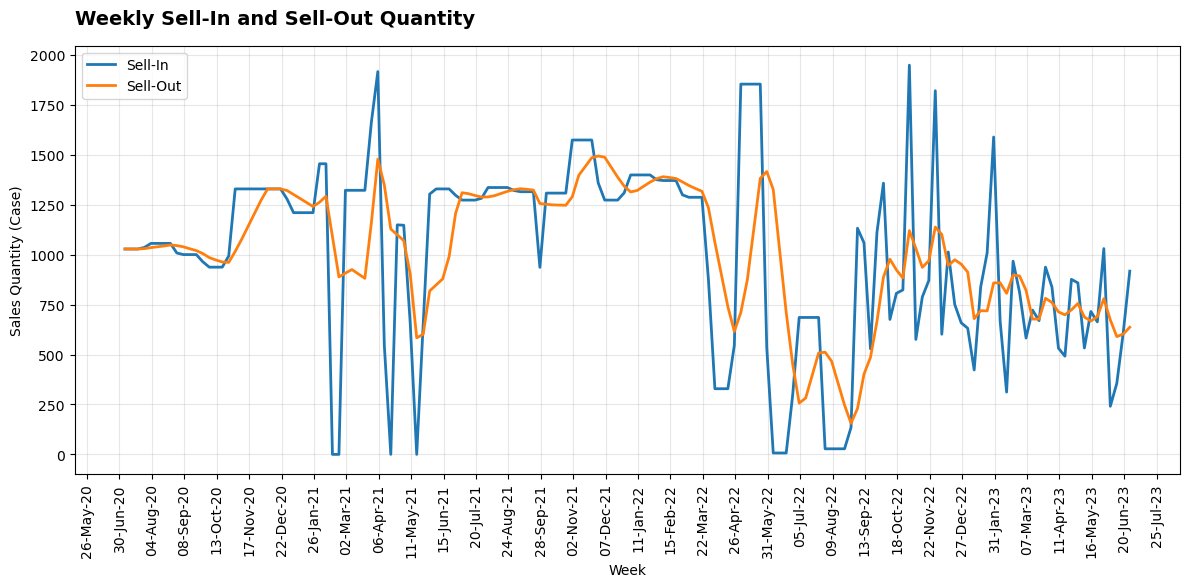

In [8]:
# Define colors and labels
colors = {'sellin': '#1f77b4', 'sellout': '#ff7f0e'}  # Blue and Orange
labels = {'sellin': 'Sell-In', 'sellout': 'Sell-Out'}

fig, ax = plt.subplots(figsize=(12, 6))

for sales_type in sales_combined['sales_key'].unique():
    sales_data = sales_combined[sales_combined['sales_key'] == sales_type]
    ax.plot(sales_data['date'], sales_data['combined_spice_masala'],
            color=colors[sales_type], linewidth=2, label=labels[sales_type])

# Title
ax.text(0.0, 1.05, "Weekly Sell-In and Sell-Out Quantity",
        transform=ax.transAxes, fontweight='bold',
        fontsize=14, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Sales Quantity (Case)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b-%y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# Adjust layout
plt.subplots_adjust(top=0.9)
plt.tight_layout()
plt.show()


Full Period Cumulative Analysis:


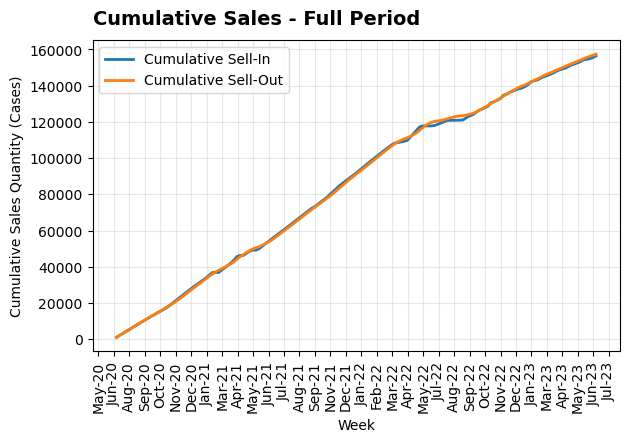

In [9]:
# Calculate cumulative sales by sales_key
cumulative_sales = []
for sales_type in sales_combined['sales_key'].unique():
    sales_data = sales_combined[sales_combined['sales_key'] == sales_type].copy()
    sales_data['cumulative_sales'] = sales_data['combined_spice_masala'].cumsum()
    cumulative_sales.append(sales_data)

cumulative_sales = pd.concat(cumulative_sales, ignore_index=True)

# Create cumulative sales plot for full period
fig, ax = plt.subplots()

# Define colors and labels
colors = {'sellin': '#1f77b4', 'sellout': '#ff7f0e'}  # Blue and Orange
labels = {'sellin': 'Cumulative Sell-In', 'sellout': 'Cumulative Sell-Out'}

# Plot cumulative lines for each sales type
for sales_type in cumulative_sales['sales_key'].unique():
   sales_data = cumulative_sales[cumulative_sales['sales_key'] == sales_type]
   ax.plot(sales_data['date'], sales_data['cumulative_sales'], 
           color=colors[sales_type], linewidth=2, label=labels[sales_type])

# Title
ax.text(0.0, 1.05, "Cumulative Sales - Full Period", 
       transform=ax.transAxes, fontweight='bold', 
       fontsize=14, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Cumulative Sales Quantity (Cases)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# Display full period plot
print("Full Period Cumulative Analysis:")
plt.subplots_adjust(top=1.9)
plt.tight_layout()
plt.show()

In [10]:
# Prepare time series data properly
sales_ts_data = sales_combined[['date', 'sales_key', 'combined_spice_masala']].pivot_table(
   index='date', 
   columns='sales_key', 
   values='combined_spice_masala'
).reset_index()

# Load the decomposed data from R

from statsmodels.tsa.seasonal import STL



sellin_decomposed = STL(sales_ts_data["sellin"], period=52,robust=True)
res_stl_sellin = sellin_decomposed.fit()

dcmp_sellin = pd.DataFrame({
    "date": sales_ts_data["date"],
    "sellin": sales_ts_data["sellin"],
    "trend": res_stl_sellin.trend,
    "seasonal": res_stl_sellin.seasonal,
    "remainder": res_stl_sellin.resid
}).reset_index(drop=True)

dcmp_sellin = dcmp_sellin.assign(sellin_deseasonalized = dcmp_sellin['sellin']-dcmp_sellin['seasonal'])

sellout_decomposed = STL(sales_ts_data["sellout"], period=52,robust=True)
res_stl_sellout = sellin_decomposed.fit()

dcmp_sellout = pd.DataFrame({
    "date": sales_ts_data["date"],
    "sellout": sales_ts_data["sellout"],
    "trend": res_stl_sellout.trend,
    "seasonal": res_stl_sellout.seasonal,
    "remainder": res_stl_sellout.resid
}).reset_index(drop=True)

dcmp_sellout = dcmp_sellout.assign(sellout_deseasonalized = dcmp_sellout['sellout']-dcmp_sellout['seasonal'])
 


# Convert date column to datetime if needed
sales_ts_data['date'] = pd.to_datetime(sales_ts_data['date'])

# Add the R-generated deseasonalized components
sales_ts_data['sellin_deseasonalized'] = dcmp_sellin['sellin_deseasonalized'].round(0)
sales_ts_data['sellout_deseasonalized'] = dcmp_sellout['sellout_deseasonalized'].round(0)

print("After adding R STL results:")
print(sales_ts_data.head().to_string(index=False))

After adding R STL results:
      date  sellin  sellout  sellin_deseasonalized  sellout_deseasonalized
2020-07-06  1029.0   1029.0                 1063.0                  1063.0
2020-07-13  1029.0   1029.0                 1063.0                  1063.0
2020-07-20  1029.0   1029.0                 1064.0                  1064.0
2020-07-27  1037.0   1031.0                 1064.0                  1058.0
2020-08-03  1057.0   1036.0                 1064.0                  1043.0


In [11]:
# Calculate bullwhip summary for recent period
recent_data = sales_ts_data[sales_ts_data['date'] > '2022-12-31']

# Calculate coefficients of variation
cov_sellin = recent_data['sellin_deseasonalized'].std() / recent_data['sellin_deseasonalized'].mean()
cov_sellout = recent_data['sellout_deseasonalized'].std() / recent_data['sellout_deseasonalized'].mean()

# Calculate bullwhip amplification factor
bullwhip_cov_ratio = (cov_sellin - cov_sellout) / cov_sellout

# Create summary dataframe
bullwhip_summary = pd.DataFrame({
   'cov_sellin': [cov_sellin],
   'cov_sellout': [cov_sellout], 
   'bullwhip_cov_ratio': [bullwhip_cov_ratio]
})

print(bullwhip_summary)

   cov_sellin  cov_sellout  bullwhip_cov_ratio
0    0.073252     0.400329           -0.817019


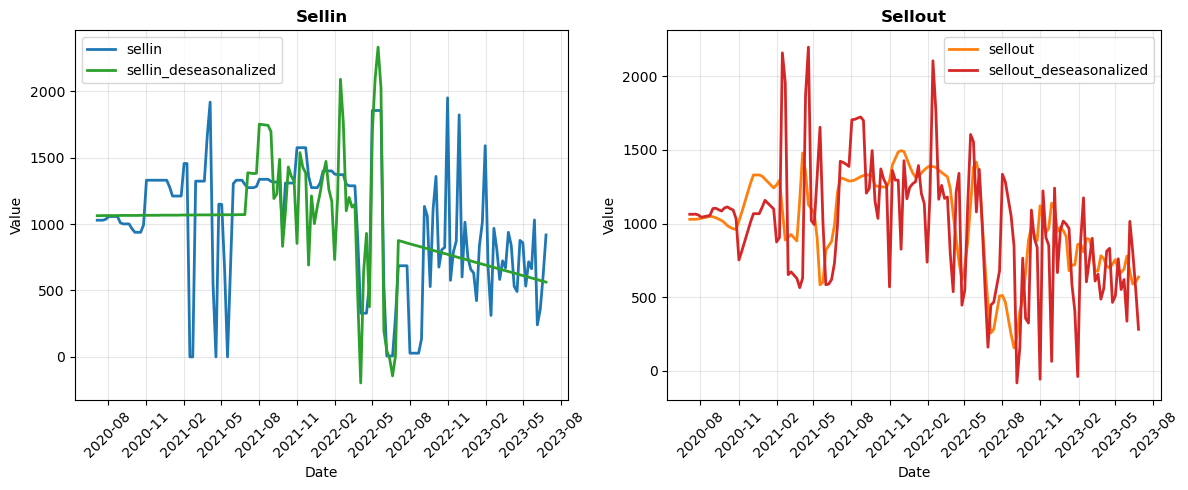

In [12]:
# Visualization of original vs deseasonalized data
plot_data = sales_ts_data.melt(
   id_vars=['date'], 
   value_vars=['sellin', 'sellout', 'sellin_deseasonalized', 'sellout_deseasonalized'],
   var_name='key', value_name='value'
)
plot_data['sales_type'] = plot_data['key'].str.contains('sellin').map({True: 'sellin', False: 'sellout'})

# Create subplots for faceting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Define colors for different series
colors = {
   'sellin': '#1f77b4',
   'sellout': '#ff7f0e', 
   'sellin_deseasonalized': '#2ca02c',
   'sellout_deseasonalized': '#d62728'
}

# Plot sellin data
sellin_data = plot_data[plot_data['sales_type'] == 'sellin']
for key in sellin_data['key'].unique():
   key_data = sellin_data[sellin_data['key'] == key]
   ax1.plot(key_data['date'], key_data['value'], 
            color=colors[key], linewidth=2, label=key)

ax1.set_title('Sellin', fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Value')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot sellout data
sellout_data = plot_data[plot_data['sales_type'] == 'sellout']
for key in sellout_data['key'].unique():
   key_data = sellout_data[sellout_data['key'] == key]
   ax2.plot(key_data['date'], key_data['value'], 
            color=colors[key], linewidth=2, label=key)

ax2.set_title('Sellout', fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Value')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Format dates on x-axis for both subplots
for ax in [ax1, ax2]:
   ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
   ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
   plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

In [13]:
# Rolling window calculation using pandas rolling
window_size = 78

def calculate_bullwhip_cov(group):
   if len(group) < window_size:
       return np.nan
   
   sellin_vals = group['sellin_deseasonalized'].iloc[-window_size:]
   sellout_vals = group['sellout_deseasonalized'].iloc[-window_size:]
   
   cov_in = sellin_vals.std() / sellin_vals.mean()
   cov_out = sellout_vals.std() / sellout_vals.mean()
   
   if pd.isna(cov_out) or cov_out <= 0:
       return np.nan
   
   return (cov_in - cov_out) / cov_out

# Calculate rolling bullwhip using expanding window then taking last window_size
bullwhip_ts = sales_ts_data.copy()
bullwhip_cov_list = []

for i in range(len(sales_ts_data)):
   if i < window_size - 1:
       bullwhip_cov_list.append(np.nan)
   else:
       window_data = sales_ts_data.iloc[i-window_size+1:i+1]
       bullwhip_val = calculate_bullwhip_cov(window_data)
       bullwhip_cov_list.append(bullwhip_val)

bullwhip_ts['bullwhip_cov'] = bullwhip_cov_list

print(bullwhip_ts[['date', 'sellin_deseasonalized', 'sellout_deseasonalized', 'bullwhip_cov']].head().to_string(index = False))

      date  sellin_deseasonalized  sellout_deseasonalized  bullwhip_cov
2020-07-06                 1063.0                  1063.0           NaN
2020-07-13                 1063.0                  1063.0           NaN
2020-07-20                 1064.0                  1064.0           NaN
2020-07-27                 1064.0                  1058.0           NaN
2020-08-03                 1064.0                  1043.0           NaN


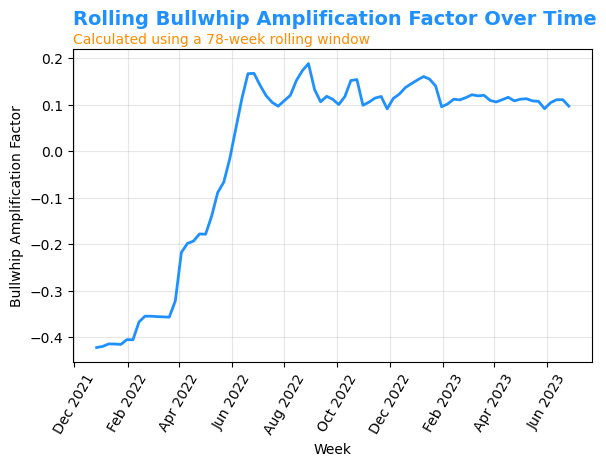

In [14]:
# Plot rolling bullwhip amplification factor
plot_data = bullwhip_ts.dropna(subset=['bullwhip_cov'])

fig, ax = plt.subplots()

# Plot the bullwhip amplification factor line
ax.plot(plot_data['date'], plot_data['bullwhip_cov'], 
       color="#1E90FF", linewidth=2)

# Title and subtitle
ax.text(0.0, 1.08, "Rolling Bullwhip Amplification Factor Over Time", 
       transform=ax.transAxes, fontweight='bold', color='#1E90FF',
       fontsize=14, ha='left')

ax.text(0.0, 1.02, f"Calculated using a {window_size}-week rolling window", 
       transform=ax.transAxes, color='#FF8C00', fontsize=10, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Bullwhip Amplification Factor")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=60)

# Grid
ax.grid(True, alpha=0.3)

# Adjust layout to accommodate titles
plt.subplots_adjust(top=0.85)
plt.tight_layout()
plt.show()

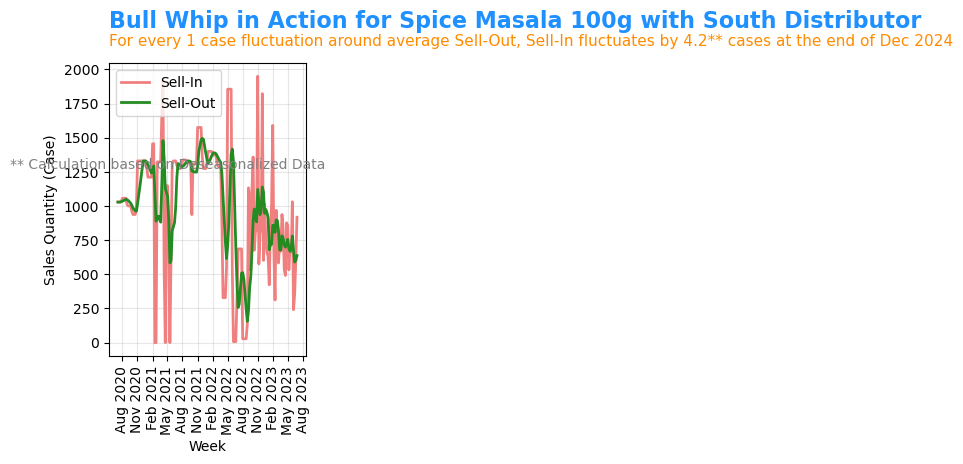

In [15]:
# Create the plot
fig, ax = plt.subplots()

# Define colors
colors = {"sellin": "#F08080", "sellout": "#228B22"}
labels = {"sellin": "Sell-In", "sellout": "Sell-Out"}

# Plot lines for each sales type
for sales_type in sales_combined['sales_key'].unique():
   sales_data = sales_combined[sales_combined['sales_key'] == sales_type]
   ax.plot(sales_data['date'], sales_data['combined_spice_masala'], 
           color=colors[sales_type], linewidth=2, label=labels[sales_type])

# Title and subtitle with proper spacing and colors
ax.text(0.0, 1.12, "Bull Whip in Action for Spice Masala 100g with South Distributor", 
       transform=ax.transAxes, fontweight='bold', color='#1E90FF', 
       fontsize=16, ha='left')

ax.text(0.0, 1.06, "For every 1 case fluctuation around average Sell-Out, Sell-In fluctuates by 4.2** cases at the end of Dec 2024", 
       transform=ax.transAxes, color='#FF8C00', fontsize=11, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Sales Quantity (Case)")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Add annotation
ax.text(pd.to_datetime("2023-12-15"), 1250, 
       "** Calculation based on Deseasonalized Data",
       ha='right', va='bottom', fontsize=10, color='gray')

# Legend and grid
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# Adjust layout to accommodate titles
plt.subplots_adjust(top=0.82)
plt.tight_layout()
plt.show()

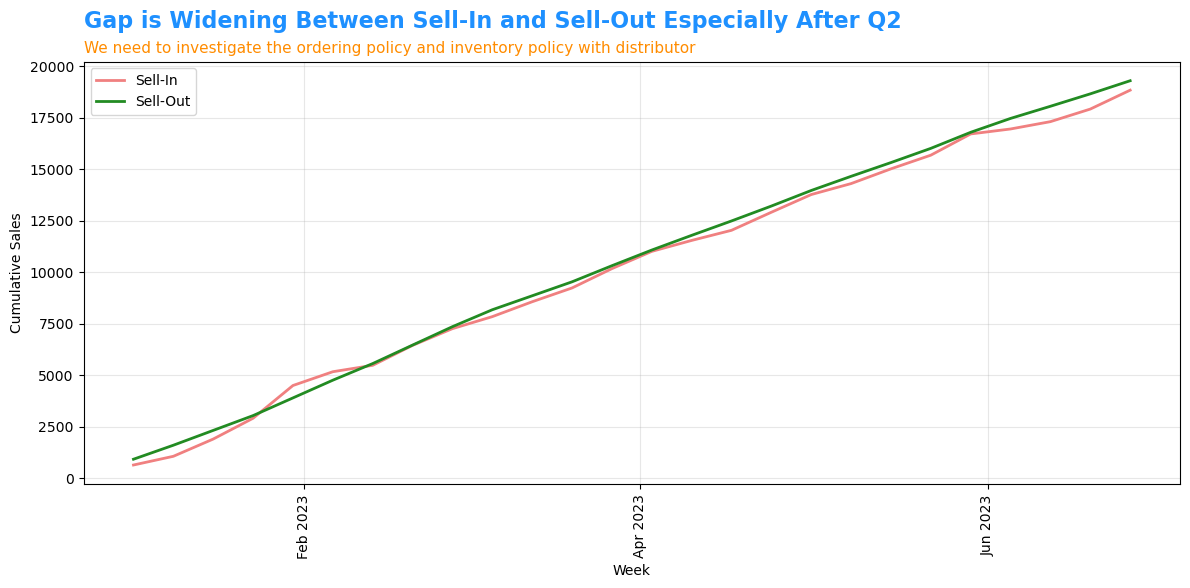

In [20]:
# Set up colors and labels
colors = {"sellin": "#F08080", "sellout": "#228B22"}
labels = {"sellin": "Sell-In", "sellout": "Sell-Out"}

fig, ax = plt.subplots(figsize=(12,6))

# Plot cumulative lines for each sales type
for sales_type in sales_2023['sales_key'].unique():
    sales_data = sales_2023[sales_2023['sales_key'] == sales_type]
    ax.plot(sales_data['date'], sales_data['cumulative_sales'],
            color=colors[sales_type], linewidth=2, label=labels[sales_type])

# Title and subtitle
ax.text(0.0, 1.08, "Gap is Widening Between Sell-In and Sell-Out Especially After Q2",
        transform=ax.transAxes, fontweight='bold', color='#1E90FF',
        fontsize=16, ha='left')
ax.text(0.0, 1.02, "We need to investigate the ordering policy and inventory policy with distributor",
        transform=ax.transAxes, color='#FF8C00', fontsize=11, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Cumulative Sales")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Legend and grid
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# Adjust layout to accommodate titles
plt.subplots_adjust(top=0.85)
plt.tight_layout()
plt.show()


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load the data
gt_sales = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
gt_sales['date'] = pd.to_datetime(gt_sales['date'])

# Filter for 2023 data only
sales_2023 = gt_sales[gt_sales['date'].dt.year == 2023].copy()

# Sort by date to ensure proper cumulative calculation
sales_2023 = sales_2023.sort_values(['sales_key', 'date'])

# Calculate cumulative sales for each sales type
sales_2023['cumulative_sales'] = sales_2023.groupby('sales_key')['value'].cumsum()




C:\Users\ramak\AppData\Local\Temp\ipykernel_9816\1607930024.py:32: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


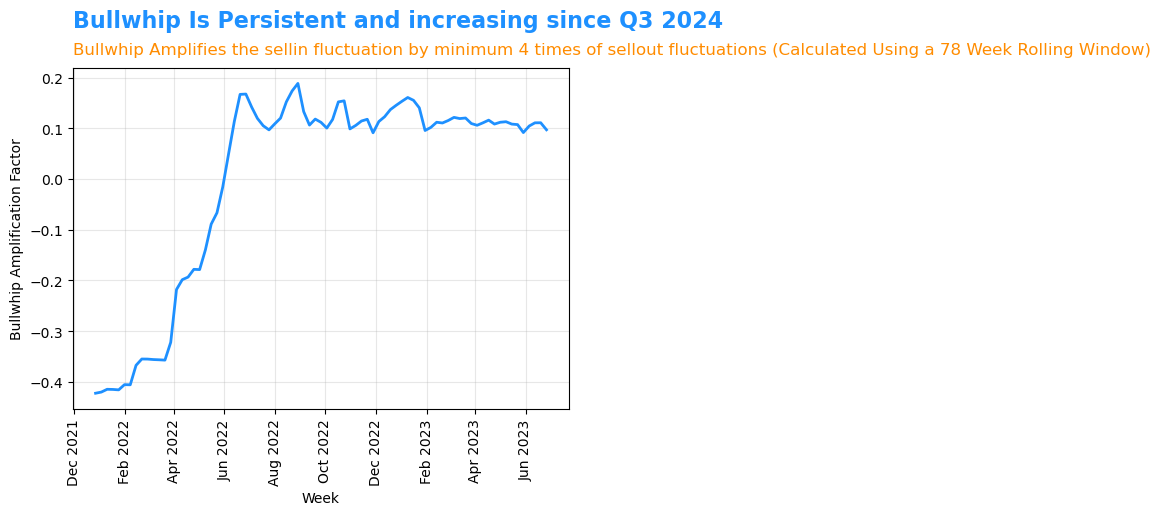

In [18]:
# Filter data
plot3_data = bullwhip_ts.dropna(subset=['bullwhip_cov'])

# Create the plot
fig, ax = plt.subplots()

# Plot the bullwhip amplification factor line
ax.plot(plot3_data['date'], plot3_data['bullwhip_cov'], 
       color="#1E90FF", linewidth=2)

# Title and subtitle with proper spacing and colors
ax.text(0.0, 1.12, "Bullwhip Is Persistent and increasing since Q3 2024", 
       transform=ax.transAxes, fontweight='bold', color='#1E90FF', 
       fontsize=16, ha='left')

ax.text(0.0, 1.04, "Bullwhip Amplifies the sellin fluctuation by minimum 4 times of sellout fluctuations (Calculated Using a 78 Week Rolling Window)", 
       transform=ax.transAxes, color='#FF8C00', fontsize=12, ha='left')

ax.set_xlabel("Week")
ax.set_ylabel("Bullwhip Amplification Factor")

# Format dates on x-axis
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)

# Grid
ax.grid(True, alpha=0.3)

# Adjust layout to accommodate titles
plt.subplots_adjust(top=0.82)
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd

# Load the data
df = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
df['date'] = pd.to_datetime(df['date'])

# For forecasting, let's use only one product (Product_13) and one sales key (e.g., 'sellin')
# If you want both sellin and sellout, you can adjust accordingly
sales_combined = df[(df['Product'] == 'Product_13') & (df['sales_key'] == 'sellin')].copy()
# If you want to forecast sellout, change 'sellin' to 'sellout'

# Ensure data is sorted by date
sales_combined = sales_combined.sort_values('date').reset_index(drop=True)

# Set the number of weeks for the test set
test_weeks = 13

# Split into train and test
train = sales_combined.iloc[:-test_weeks]
test = sales_combined.iloc[-test_weeks:]

# Check the result
print("Train period:", train['date'].min(), "to", train['date'].max())
print("Test period:", test['date'].min(), "to", test['date'].max())
print("Train size:", len(train), "Test size:", len(test))


Train period: 2020-07-06 00:00:00 to 2023-03-27 00:00:00
Test period: 2023-04-03 00:00:00 to 2023-06-26 00:00:00
Train size: 143 Test size: 13


In [22]:
import pandas as pd

# Load data
df = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
df['date'] = pd.to_datetime(df['date'])

# Filter for the sales_key and product you want to forecast
train = df[(df['Product'] == 'Product_13') & (df['sales_key'] == 'sellin')].copy()
train = train.sort_values('date').reset_index(drop=True)

from sklearn.base import BaseEstimator, TransformerMixin

class DateFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X['year'] = X['date'].dt.year
        X['month'] = X['date'].dt.month
        X['week'] = X['date'].dt.isocalendar().week
        X['dayofweek'] = X['date'].dt.dayofweek
        return X[['year', 'month', 'week', 'dayofweek']]

# Example usage:
date_features = DateFeatureExtractor().fit_transform(train[['date']])

X = date_features
y = train['value']

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(DateFeatureExtractor(), LinearRegression())
pipeline.fit(train[['date']], train['value'])


Pipeline(steps=[('datefeatureextractor', DateFeatureExtractor()),
                ('linearregression', LinearRegression())])

In [1]:
import pandas as pd
import numpy as np

# Load data
df = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
df['date'] = pd.to_datetime(df['date'])

# Filter for sellin and Product_13
df = df[(df['Product'] == 'Product_13') & (df['sales_key'] == 'sellin')].copy()
df = df.sort_values('date').reset_index(drop=True)

# Add promo_key (example: if price < rolling median, it's a promo)
df['promo_key'] = (df['sellin_price'] < df['sellin_price'].rolling(window=8, min_periods=1).median()).astype(int)

# Time series signature features
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['week'] = df['date'].dt.isocalendar().week.astype(int)
df['dayofweek'] = df['date'].dt.dayofweek
df['year'] = df['date'].dt.year

# Drop columns not needed for modeling
X = df[['date', 'promo_key', 'month', 'quarter', 'week', 'dayofweek', 'year']]
y = df['value']


In [2]:
test_weeks = 13
X_train, X_test = X.iloc[:-test_weeks], X.iloc[-test_weeks:]
y_train, y_test = y.iloc[:-test_weeks], y.iloc[-test_weeks:]


In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_model = ExponentialSmoothing(
    y_train,
    trend='add',
    seasonal='add',
    seasonal_periods=52  # yearly seasonality in weekly data
).fit()
ets_forecast = ets_model.forecast(steps=test_weeks)


In [4]:
pip install pmdarima prophet tbats

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [ ]:
import pmdarima as pm

arima_model = pm.auto_arima(
    y_train,
    seasonal=True,
    m=52,  # yearly seasonality in weekly data
    stepwise=True,
    suppress_warnings=True
)
arima_forecast = arima_model.predict(n_periods=test_weeks)

from tbats import TBATS

tbats_estimator = TBATS(seasonal_periods=[52])
tbats_model = tbats_estimator.fit(y_train)
tbats_forecast = tbats_model.forecast(steps=test_weeks)

forecast_df = pd.DataFrame({
    'date': X_test['date'].values,
    'actual': y_test.values,
    'ETS': ets_forecast.values if hasattr(ets_forecast, 'values') else ets_forecast,
    'ARIMA': arima_forecast,
    'Prophet': prophet_forecast.values if hasattr(prophet_forecast, 'values') else prophet_forecast,
    'TBATS': tbats_forecast
})


In [ ]:
import pandas as pd
import numpy as np

# Load data
df = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
df['date'] = pd.to_datetime(df['date'])

# Filter for sell-in and Product_13
df = df[(df['Product'] == 'Product_13') & (df['sales_key'] == 'sellin')].copy()
df = df.sort_values('date').reset_index(drop=True)

# Create promo_key: 1 if price is below rolling median (example logic)
df['promo_key'] = (df['sellin_price'] < df['sellin_price'].rolling(window=8, min_periods=1).median()).astype(int)

# Time features (like step_timeseries_signature in R)
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['week'] = df['date'].dt.isocalendar().week.astype(int)
df['dayofweek'] = df['date'].dt.dayofweek
df['year'] = df['date'].dt.year

# Drop rows with missing target
df = df.dropna(subset=['value'])

# Select features and target
features = ['promo_key', 'month', 'quarter', 'week', 'dayofweek', 'year']
X = df[features]
y = df['value']

test_weeks = 13
X_train, X_test = X.iloc[:-test_weeks], X.iloc[-test_weeks:]
y_train, y_test = y.iloc[:-test_weeks], y.iloc[-test_weeks:]


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

from xgboost import XGBRegressor

xgb_model = XGBRegressor(random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

import lightgbm as lgb

lgbm_model = lgb.LGBMRegressor(random_state=42, n_jobs=-1)
lgbm_model.fit(X_train, y_train)
lgbm_pred = lgbm_model.predict(X_test)

results = pd.DataFrame({
    'date': df['date'].iloc[-test_weeks:],
    'actual': y_test,
    'RandomForest': rf_pred,
    'XGBoost': xgb_pred,
    'LightGBM': lgbm_pred
})


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import pmdarima as pm
from prophet import Prophet
from tbats import TBATS

# Load and prepare the data
df = pd.read_excel("bullwhip.xlsx", sheet_name="Sheet1")
df = df[(df['Product'] == 'Product_13') & (df['sales_key'] == 'sellin')].copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
df = df[['date', 'value']].dropna()

# Split into train and test (last 13 weeks for test)
test_weeks = 13
train = df.iloc[:-test_weeks]
test = df.iloc[-test_weeks:]

# --- ETS ---
ets_model = ExponentialSmoothing(
    train['value'],
    trend='add',
    seasonal='add',
    seasonal_periods=52
).fit()
ets_forecast = ets_model.forecast(test_weeks)

# --- ARIMA ---
arima_model = pm.auto_arima(
    train['value'],
    seasonal=True,
    m=52,
    stepwise=True,
    suppress_warnings=True
)
arima_forecast = arima_model.predict(n_periods=test_weeks)

# --- Prophet ---
prophet_train = train.rename(columns={'date': 'ds', 'value': 'y'})
prophet_model = Prophet(weekly_seasonality=True, daily_seasonality=False, yearly_seasonality=False)
prophet_model.fit(prophet_train)
future = prophet_model.make_future_dataframe(periods=test_weeks, freq='W')
prophet_forecast = prophet_model.predict(future).set_index('ds')['yhat'][-test_weeks:]

# --- TBATS ---
tbats_estimator = TBATS(seasonal_periods=[52])
tbats_model = tbats_estimator.fit(train['value'])
tbats_forecast = tbats_model.forecast(steps=test_weeks)

# --- Plotting ---
plt.figure(figsize=(16, 7))
plt.plot(df['date'], df['value'], label='Actual', color='black', linewidth=2)
plt.plot(test['date'], ets_forecast, label='ETS Forecast', color='#1f77b4', linestyle='--')
plt.plot(test['date'], arima_forecast, label='ARIMA Forecast', color='#ff7f0e', linestyle='--')
plt.plot(test['date'], prophet_forecast, label='Prophet Forecast', color='#2ca02c', linestyle='--')
plt.plot(test['date'], tbats_forecast, label='TBATS Forecast', color='#d62728', linestyle='--')

plt.title('Sell-In Forecasts: ETS, ARIMA, Prophet, TBATS', fontsize=16, fontweight='bold')
plt.xlabel('Week')
plt.ylabel('Sell-In Quantity')
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
